In [1]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt  # isso eh pra gerar os graficos

import numpy as np

In [2]:
iris = load_iris() # carrega todo o database para a variavel iris
X = iris.data # extrai matriz bidimensional, onde as linhas são os exemplos(amostras) e as colunas sao as caracteristicas (features)
# na iris eh matriz com os 4 atributos
y = iris.target # extrai o vetor unidimensional com as classes verdadeiras (rótulos-alvo)

In [3]:
print("Amostras e atributos:", X.shape)
print("Atributos:", iris.feature_names)
print("Classes:", iris.target_names)


Amostras e atributos: (150, 4)
Atributos: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']


In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size = 0.3, 
    random_state=42, stratify= y
)
# random_state=42 embaralha as amostras, pra q a divisao seja sempre exatamente o mesmo em qualquer execução
# stratify= y faz a estratificação nos rótulos verdadeiros, 
# pra garantir proporção idêntica de classes em ambos os lados: 35 flores de cada classe no treino e 15 flores de cada classe no teste
print("Treino:", len(y_treino), "Teste:", len(y_teste))

Treino: 105 Teste: 45


In [5]:
modelo = DecisionTreeClassifier(
criterion="gini", max_depth=3, random_state=42
)
modelo.fit(X_treino, y_treino) # construir a arv de acordo com o treino
y_pred = modelo.predict(X_teste) # testar a arv, prever os rotulos das amostras do teste 
print("Primeiras previsões:", y_pred[:5])

Primeiras previsões: [2 1 2 1 2]


In [7]:
acuracia = accuracy_score(y_teste, y_pred)
matriz = confusion_matrix(y_teste, y_pred)
print(f"Acurácia: {acuracia:.3f}")
print("Matriz de confusão:\n", matriz)

Acurácia: 0.978
Matriz de confusão:
 [[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]


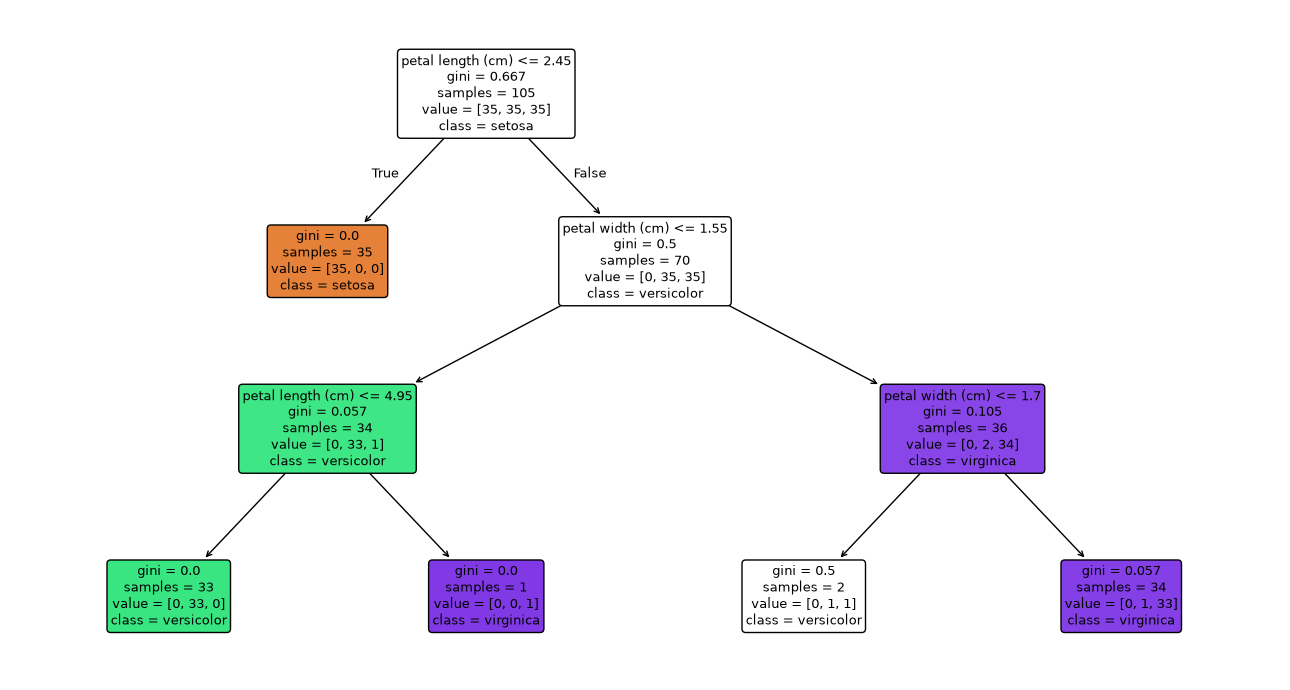

In [8]:
plt.figure(figsize=(13, 7))
plot_tree(modelo, feature_names=iris.feature_names,
class_names=iris.target_names, filled=True,
rounded=True, fontsize=9)
plt.tight_layout()
plt.show()

In [9]:
for profundidade in [1, 2, 3, None]:
    arvore = DecisionTreeClassifier(
        criterion="gini", max_depth=profundidade,
        random_state=42
    )
    arvore.fit(X_treino, y_treino)
    acc_treino = accuracy_score(
        y_treino, arvore.predict(X_treino))
    acc_teste = accuracy_score(
        y_teste, arvore.predict(X_teste))
    print(profundidade, f"{acc_treino:.3f}",
        f"{acc_teste:.3f}")

1 0.667 0.667
2 0.971 0.889
3 0.981 0.978
None 1.000 0.933
